In [6]:
import h5py

h5_path = "../datasets/features/BC1/uni/SPA154.h5"
h5_path = "../datasets/features/BC1/uni/SPA154.h5"

with h5py.File(h5_path, "r") as f:
    print(f.keys())
    gene_list = f["gene_list"][:]
    print(gene_list.shape)
    print("num genes:", len(gene_list))
    print(gene_list[:10])

<KeysViewHDF5 ['barcode', 'coords', 'count', 'exp', 'features', 'gene_list', 'patient', 'sample']>
<KeysViewHDF5 ['barcode', 'coords', 'count', 'exp', 'features', 'gene_list', 'patient', 'sample']>
(12041,)
num genes: 12041
[b'FO538757.1' b'SAMD11' b'NOC2L' b'KLHL17' b'PLEKHN1' b'PERM1' b'HES4'
 b'ISG15' b'AGRN' b'RNF223']


In [2]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

cluster_dir = "../datasets/clustered/BC1_0p3"
h5ad_files = sorted(glob.glob(os.path.join(cluster_dir, "**", "*.h5ad"), recursive=True))

if not h5ad_files:
    raise FileNotFoundError(f"No h5ad files found under {cluster_dir}")

adata_list = []
for path in h5ad_files:
    ad = sc.read_h5ad(path)
    if "patient_id" not in ad.obs.columns:
        raise KeyError(f"{path} does not contain 'patient_id' in adata.obs")
    if "sample_id" not in ad.obs.columns:
        raise KeyError(f"{path} does not contain 'sample_id' in adata.obs")
    adata_list.append(ad)

adata = sc.concat(
    adata_list,
    join="inner",
    index_unique=None,
    merge="same",
)

cluster_cols = sorted([col for col in adata.obs.columns if col.endswith("_cluster")])
if not cluster_cols:
    raise ValueError("No cluster columns found in adata.obs")

patient_col = "patient_id"
summary_rows = []
for cluster_col in cluster_cols:
    feature_name = cluster_col.removesuffix("_cluster")
    for patient_id in adata.obs[patient_col].dropna().unique():
        sub = adata[adata.obs[patient_col] == patient_id]
        cluster_values = sub.obs[cluster_col].dropna().astype(str)
        summary_rows.append(
            {
                "patient_id": patient_id,
                "feature": feature_name,
                "n_clusters": int(cluster_values.nunique()),
            }
        )

summary_df = pd.DataFrame(summary_rows)
cluster_count_table = summary_df.pivot(
    index="patient_id",
    columns="feature",
    values="n_clusters",
).fillna(0).astype(int)

print("每个 patient 在每个 feature 下的 cluster 数量：")
display(cluster_count_table)



每个 patient 在每个 feature 下的 cluster 数量：


feature,midnight,resnet50,uni
patient_id,,,
Patient A,6,4,5
Patient B,5,3,3
Patient C,5,3,3
Patient D,6,3,2
Patient E,4,3,4
Patient F,5,3,4
Patient G,4,4,3
Patient H,6,5,5


每个 rank list 的 gene 数量：


conch       250
uni         250
resnet50    250
midnight    250
Name: n_genes, dtype: int64

两两 overlap 数量 inclusive：


,conch,uni,resnet50,midnight
conch,250,210,198,205
uni,210,250,198,202
resnet50,198,198,250,193
midnight,205,202,193,250


2/3/4 个 rank list 的 overlap 数量 inclusive：


,n_lists,lists,n_overlap_inclusive
0,2,conch & uni,210
1,2,conch & midnight,205
2,2,uni & midnight,202
3,2,conch & resnet50,198
4,2,uni & resnet50,198
5,2,resnet50 & midnight,193
6,3,conch & uni & midnight,190
7,3,conch & uni & resnet50,184
8,3,conch & resnet50 & midnight,178
9,3,uni & resnet50 & midnight,175


容斥分区数量 exact，仅展示属于至少 2 个 list 的 gene：


,lists,n_lists,n_genes_exact
0,conch & uni & resnet50 & midnight,4,171
1,conch & uni & midnight,3,19
2,conch & uni & resnet50,3,13
3,conch & resnet50 & midnight,3,7
4,uni & resnet50 & midnight,3,4
5,resnet50 & midnight,2,11
6,uni & resnet50,2,10
7,conch & midnight,2,8
8,uni & midnight,2,8
9,conch & uni,2,7


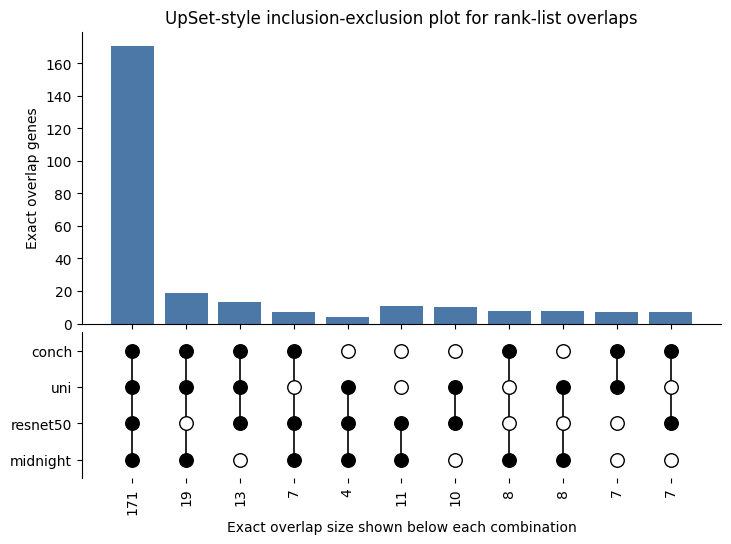

In [1]:
import json
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

rank_dir_candidates = [Path("../datasets/rank_list"), Path("datasets/rank_list")]
rank_dir = next((path for path in rank_dir_candidates if path.exists()), rank_dir_candidates[0])
rank_files = {
    "conch": rank_dir / "conch_fscore.json",
    "uni": rank_dir / "uni_fscore_0p3.json",
    "resnet50": rank_dir / "resnet50_fscore_0p3.json",
    "midnight": rank_dir / "midnight_fscore_0p3.json",
}

gene_sets = {}
for name, rank_path in rank_files.items():
    with open(rank_path, "r", encoding="utf-8") as f:
        gene_sets[name] = set(json.load(f))

names = list(gene_sets.keys())

print("每个 rank list 的 gene 数量：")
display(pd.Series({name: len(genes) for name, genes in gene_sets.items()}, name="n_genes"))

# Inclusive overlap: A & B includes genes that may also appear in C/D.
pairwise_df = pd.DataFrame(index=names, columns=names, dtype=int)
for row_name, row_genes in gene_sets.items():
    for col_name, col_genes in gene_sets.items():
        pairwise_df.loc[row_name, col_name] = len(row_genes & col_genes)

print("两两 overlap 数量 inclusive：")
display(pairwise_df.astype(int))

combo_rows = []
for n_lists in range(2, len(names) + 1):
    for combo in combinations(names, n_lists):
        overlap = set.intersection(*(gene_sets[name] for name in combo))
        combo_rows.append(
            {
                "n_lists": n_lists,
                "lists": " & ".join(combo),
                "n_overlap_inclusive": len(overlap),
            }
        )

combo_df = (
    pd.DataFrame(combo_rows)
    .sort_values(["n_lists", "n_overlap_inclusive"], ascending=[True, False])
    .reset_index(drop=True)
)

print("2/3/4 个 rank list 的 overlap 数量 inclusive：")
display(combo_df)

# Exact overlap partitions for an UpSet-style inclusion-exclusion plot.
# Example: conch & uni means genes in exactly conch and uni, not in the others.
all_genes = set.union(*gene_sets.values())
pattern_counts = Counter(
    tuple(name for name in names if gene in gene_sets[name])
    for gene in all_genes
)

exact_df = pd.DataFrame(
    [
        {
            "members": pattern,
            "lists": " & ".join(pattern),
            "n_lists": len(pattern),
            "n_genes_exact": count,
        }
        for pattern, count in pattern_counts.items()
        if len(pattern) >= 2
    ]
).sort_values(["n_lists", "n_genes_exact"], ascending=[False, False]).reset_index(drop=True)

print("容斥分区数量 exact，仅展示属于至少 2 个 list 的 gene：")
display(exact_df[["lists", "n_lists", "n_genes_exact"]])

fig_width = max(8, len(exact_df) * 0.75)
fig = plt.figure(figsize=(fig_width, 5.8))
grid = fig.add_gridspec(2, 1, height_ratios=[3.2, 1.6], hspace=0.04)
ax_bar = fig.add_subplot(grid[0])
ax_matrix = fig.add_subplot(grid[1], sharex=ax_bar)

x = list(range(len(exact_df)))
ax_bar.bar(x, exact_df["n_genes_exact"], color="#4C78A8")
ax_bar.set_ylabel("Exact overlap genes")
ax_bar.set_title("UpSet-style inclusion-exclusion plot for rank-list overlaps")
ax_bar.tick_params(axis="x", labelbottom=False)

for i, members in enumerate(exact_df["members"]):
    member_y = [names.index(name) for name in members]
    ax_matrix.plot([i, i], [min(member_y), max(member_y)], color="black", linewidth=1.2)
    for y, name in enumerate(names):
        selected = name in members
        ax_matrix.scatter(
            i,
            y,
            s=95,
            color="black" if selected else "white",
            edgecolor="black",
            linewidth=1,
            zorder=3,
        )

ax_matrix.set_yticks(range(len(names)))
ax_matrix.set_yticklabels(names)
ax_matrix.set_xticks(x)
ax_matrix.set_xticklabels(exact_df["n_genes_exact"], rotation=90)
ax_matrix.set_xlabel("Exact overlap size shown below each combination")
ax_matrix.set_ylim(-0.5, len(names) - 0.5)
ax_matrix.invert_yaxis()
ax_matrix.spines[["top", "right", "bottom"]].set_visible(False)
ax_bar.spines[["top", "right"]].set_visible(False)

plt.show()
